# Lab — Value-based Methods

Two hands-on exercises. **Gridworld** applies **policy evaluation**: you build the environment, define a fixed policy and estimate its value function with TD($\lambda$). **Blackjack** applies **policy improvement**: starting from a random baseline you learn the optimal policy with Double Q-learning.

## Gridworld (policy evaluation)

Create the environment from the Russell and Norvig’s book on AI: **the Gridworld**. This environment is a 3 x 4 grid world in which the agent starts at the bottom-left corner, and it has to reach the top-right corner. There is a hole south of the goal and a wall near the start. The transition function has a 20% noise; that is, 80% the action succeeds, and 20% it fails uniformly at random in orthogonal directions. The reward function is a –0.04 living penalty, a +1 for landing on the goal, and a –1 for landing on the hole.

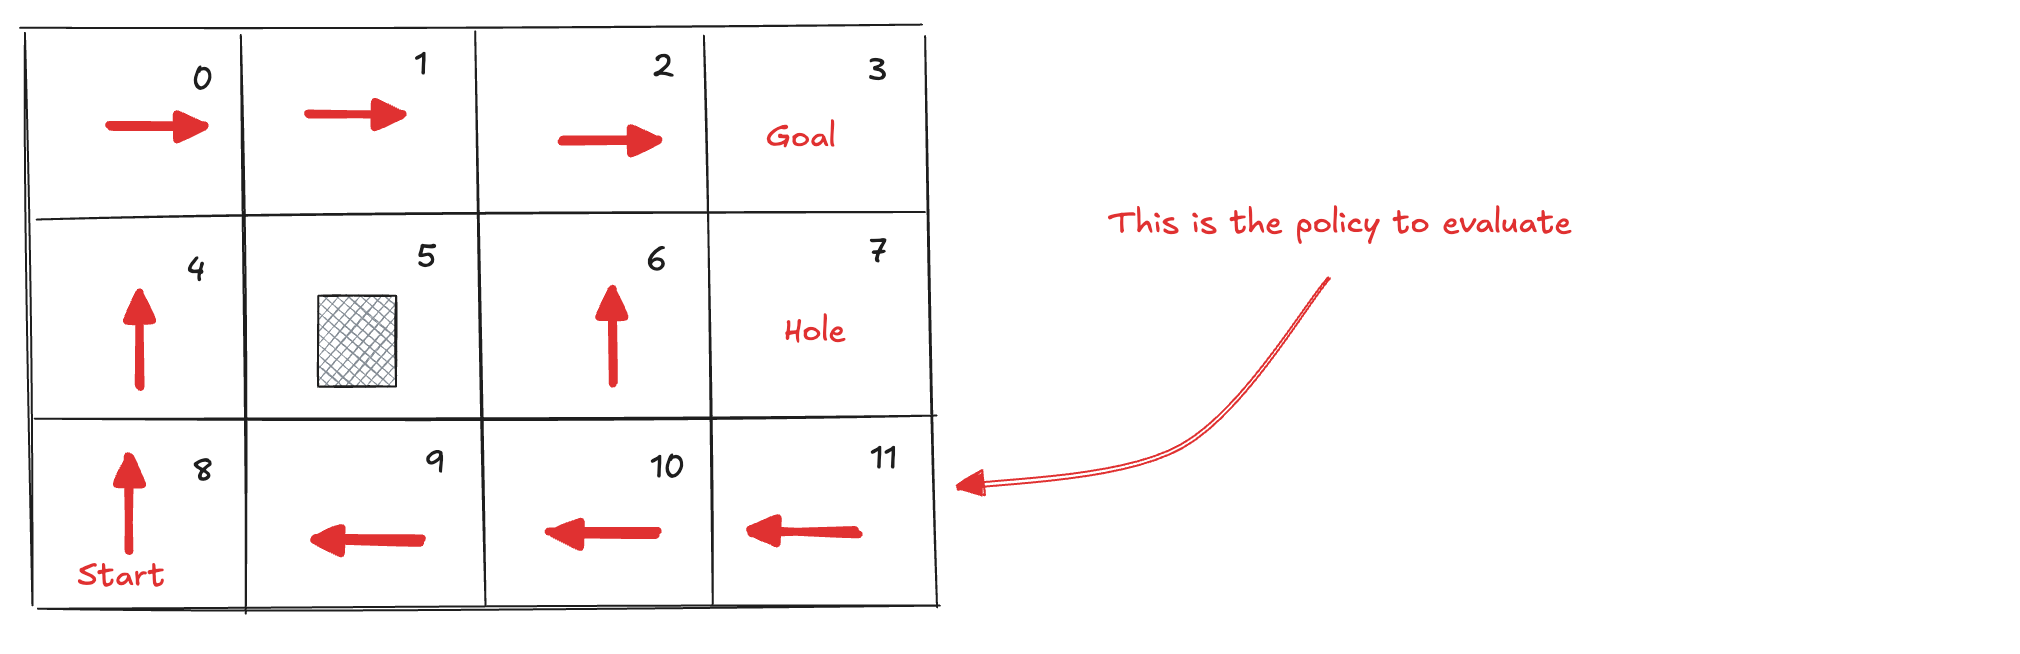


1 - Create the environment Gridworld as described above.

In [ ]:
# The environment should be a class with the following methods: 
# `__init__(self)`: initialize the environment
# `reset(self)`: reset the environment to the initial state and return it
# `step(self, action)`: take an action in the environment. The action is an 
# integer between 0 and 3, with 0 meaning up, 1 down, 2 left and 3 right.
# As for all the environments used in the notes, the method returns the  
# 5-tuple (next_state, reward, terminated, truncated, info).
# The environment should also expose its transition model in the attribute `P`,
# in the same format used in the Dynamic Programming chapter, so that the exact
# value function of a policy can be computed later and compared with the estimates.

import numpy as np

UP, DOWN, LEFT, RIGHT = range(4)

class GridWorld:
    
    # 0:UP, 1:DOWN, 2:LEFT 3:RIGHT
    
    # the goal, the hole and the wall
    GOAL, HOLE, WALL = 3, 7, 5

    def __init__(self):
        self.rows, self.columns = 3, 4
        self.nrow, self.ncol = self.rows, self.columns
        self.observation_space = self.rows * self.columns
        self.action_space = 4
        self.P = self.build_dynamics()
        self.reset()

    # where the agent ends up when it actually moves in 'direction' from 'state',
    # taking the boundaries of the grid and the wall into account
    def move(self, state, direction):
        row, column = state // self.columns, state % self.columns
        if direction == UP:    row = max(row - 1, 0)
        if direction == DOWN:  row = min(row + 1, self.rows - 1)
        if direction == LEFT:  column = max(column - 1, 0)
        if direction == RIGHT: column = min(column + 1, self.columns - 1)
        next_state = row * self.columns + column
        
        # bumping into the wall leaves the agent where it was
        return state if next_state == self.WALL else next_state

    # the reward obtained on landing, and whether the episode ends there
    def outcome(self, next_state):
        if next_state == self.GOAL: return 1.0, True
        if next_state == self.HOLE: return -1.0, True
        return -0.04, False
    
    # the orthogonal directions in which an action may fail
    def orthogonal(self, action):
        return {UP: (LEFT, RIGHT), DOWN: (LEFT, RIGHT),
                LEFT: (UP, DOWN), RIGHT: (UP, DOWN)}[action]

    # the complete transition model: P[state][action] is the list of the possible
    # transitions (probability, next_state, reward, terminated)
    def build_dynamics(self):
        P = {}
        for state in range(self.rows * self.columns):
            P[state] = {}
            for action in range(4):
                
                # nothing ever happens in the terminal states and in the wall
                if state in (self.GOAL, self.HOLE, self.WALL):
                    P[state][action] = [(1.0, state, 0.0, True)]
                    continue
                
                # the action succeeds with probability 0.8, and fails uniformly
                # at random in the two orthogonal directions
                transitions = {}
                for direction, probability in [(action, 0.8)] + [(d, 0.1) for d in self.orthogonal(action)]:
                    next_state = self.move(state, direction)
                    reward, terminated = self.outcome(next_state)
                    
                    # different directions may lead to the same transition
                    key = (next_state, reward, terminated)
                    transitions[key] = transitions.get(key, 0.0) + probability
                    
                P[state][action] = [(p, s, r, t) for (s, r, t), p in transitions.items()]
        return P

    # the Dynamic Programming functions access the model through 'unwrapped'
    @property
    def unwrapped(self):
        return self

    def reset(self):
        self.state = 8
        self.terminated = False
        self.reward = 0.0
        return self.state
    
    def step(self, action):
        if self.terminated: raise ValueError('Episode has terminated')
        if action not in (UP, DOWN, LEFT, RIGHT): raise ValueError('Invalid action')
        
        # add stochasticity: the action succeeds 80% of the times
        direction = np.random.choice([action] + list(self.orthogonal(action)), p=[0.8, 0.1, 0.1])
        
        # move, and collect the reward of the state reached
        self.state = self.move(self.state, direction)
        self.reward, self.terminated = self.outcome(self.state)
        
        return self.state, self.reward, self.terminated, False, {}

grid_world = GridWorld()

2 - Write the following policy for this environment

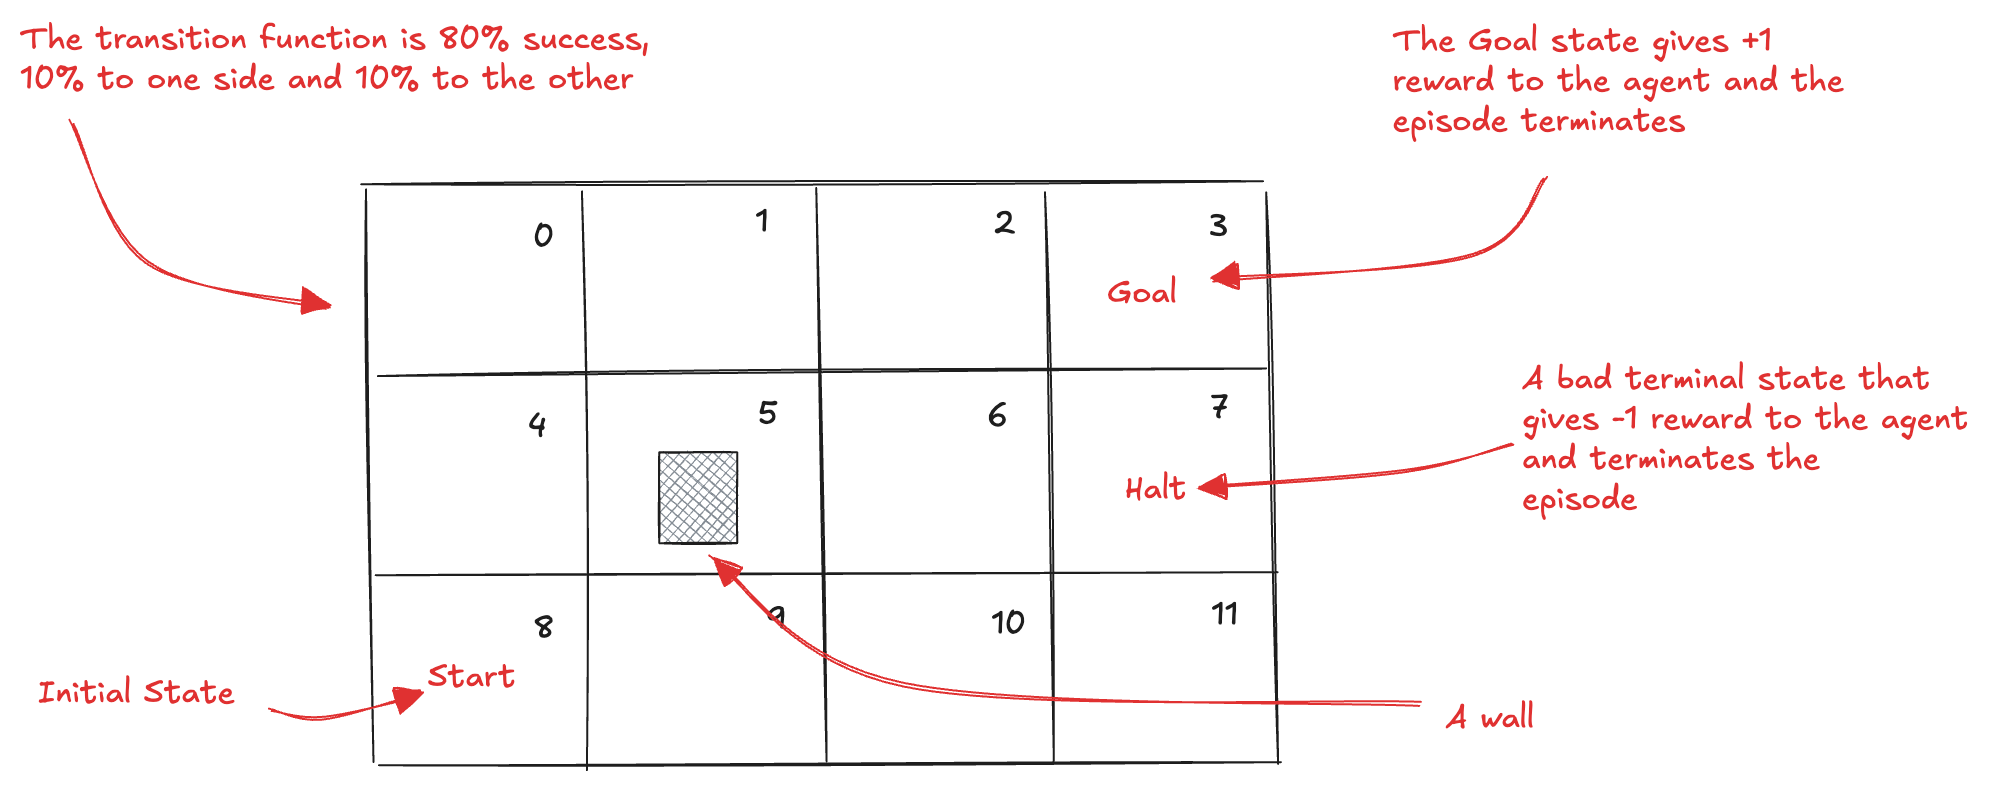

In [ ]:
# The policy should be a function that takes an integer between 0 and 11
# (the state) and returns an integer between 0 and 3 (the action).

pi = lambda s: {
    0:RIGHT, 1:RIGHT, 2:RIGHT, 3:LEFT,
    4:UP,    5:LEFT,  6:UP,    7:LEFT,
    8:UP,    9:LEFT, 10:LEFT, 11:LEFT
}[s]

3 - Show the policy by printing the selected action for each state:

In [ ]:
# The function should print the policy in a human-readable format.
# For example, the output could be:
# state: 0 -> action: RIGHT
# state: 1 -> action: RIGHT
# etc...

def print_policy(pi, env):
    for state in range(env.observation_space):
        action = pi(state)
        action_icon = ' '
        if action == UP: action_icon = 'UP'
        if action == DOWN: action_icon = 'DOWN'
        if action == LEFT: action_icon = 'LEFT'
        if action == RIGHT: action_icon = 'RIGHT'
        print('state:', state, '->', 'action:', action_icon)

print_policy(pi, grid_world)

state: 0 -> action: RIGHT
state: 1 -> action: RIGHT
state: 2 -> action: RIGHT
state: 3 -> action: LEFT
state: 4 -> action: UP
state: 5 -> action: LEFT
state: 6 -> action: UP
state: 7 -> action: LEFT
state: 8 -> action: UP
state: 9 -> action: LEFT
state: 10 -> action: LEFT
state: 11 -> action: LEFT


4 - Now, evaluate this policy using TD($\lambda$)

In [ ]:
# you need the td_lambda implementation, the same used in the notes

def td_lambda(pi, env, gamma=1.0, lambda_=0.3,
              alpha=0.1, n_episodes=500):

    # Initialize the state-value estimates
    v = np.zeros(env.observation_space, dtype=float)

    # Store the estimates after each episode
    v_track = np.zeros((n_episodes, env.observation_space), dtype=float)

    # Eligibility trace associated with every state
    E = np.zeros(env.observation_space, dtype=float)

    # Run one complete episode at a time
    for e in range(n_episodes):

        # Eligibility traces are reset at the beginning of each episode
        E.fill(0)

        state = env.reset()
        done = False

        while not done:

            # Select an action according to the policy
            action = pi(state)

            # Interact with the environment for one step
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Compute the ordinary one-step TD target and error
            td_target = reward + gamma * v[next_state] * (not done)
            td_error = td_target - v[state]

            # Make the current state eligible for credit
            E[state] = E[state] + 1

            # Propagate the current TD error to all eligible states
            v = v + alpha * td_error * E

            # Decay the eligibility traces
            E = gamma * lambda_ * E

            # Continue from the next state
            state = next_state

        # Store the value estimates after the episode
        v_track[e] = v

    return v.copy(), v_track

In [ ]:
# run the algorithm and print the value function

v_td_lambda, v_td_lambda_track = td_lambda(pi, grid_world, lambda_=0.3, n_episodes=500)
print(v_td_lambda)

[0.8415656  0.89934748 0.95800912 0.         0.79107068 0.
 0.61815666 0.         0.74072074 0.60860885 0.         0.        ]


5 - The transition model of this environment is known, so the **exact** value function of the policy can be computed by Dynamic Programming. Calculate it, and use it as a reference to judge the estimates obtained by TD($\lambda$):

In [ ]:
# Reuse the policy_evaluation function written for the Dynamic Programming chapter.
# Notice that it only needs the transition model, it never interacts with the 
# environment: this is exactly the knowledge that model-free methods do not have.

def policy_evaluation(pi, env, gamma=1.0, theta=1e-10):
    dynamics = env.unwrapped.P
    prev_V = np.zeros(len(dynamics))
    while True:
        V = np.zeros(len(dynamics))
        for s in range(len(dynamics)):
            for prob, next_state, reward, done in dynamics[s][pi(s)]:
                V[s] += prob * (reward + (0.0 if done else gamma * prev_V[next_state]))
        if np.max(np.abs(V - prev_V)) < theta:
            break
        prev_V = V.copy()
    return V

# the same gamma used for the TD(lambda) estimates
v_true = policy_evaluation(pi, grid_world, gamma=1.0)

np.set_printoptions(precision=3, suppress=True)
print("exact values  :", v_true)
print("TD(lambda)    :", v_td_lambda)
print("absolute error:", np.abs(v_td_lambda - v_true))

Look carefully at the error on **states 10 and 11**, and compare it with the error on the states that lie along the trajectory followed by the policy. Explain the difference, and say what a model-free method would need in order to estimate those two states as well. Notice that Dynamic Programming had no such difficulty.

6 - Plot the estimated value for states 8, 6 and 2 over the episodes, together with the exact values as a reference:

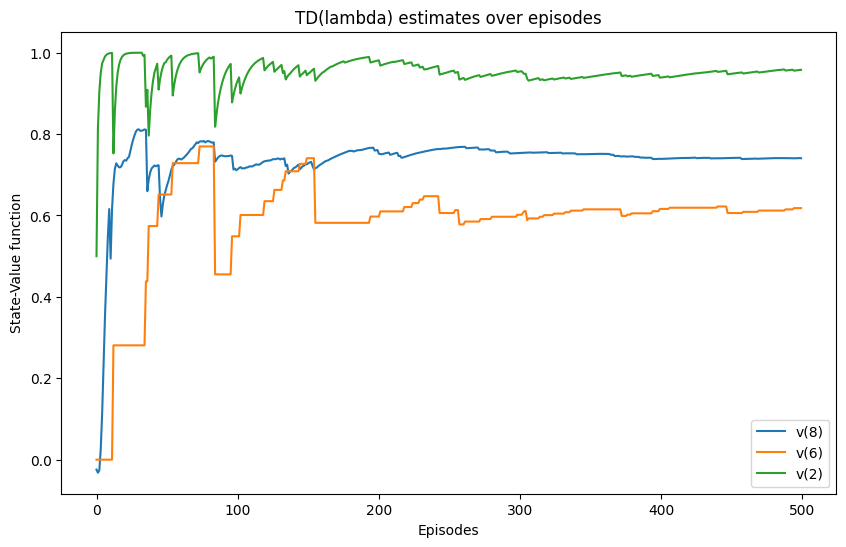

In [ ]:
# plot the value function over episodes for state 8, 6 and 2, and draw the
# exact values computed above as dashed horizontal lines

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
states = [8, 6, 2]
colors = ['tab:blue', 'tab:orange', 'tab:green']

for state, color in zip(states, colors):
    plt.plot(v_td_lambda_track[:, state], color=color, label=f'v({state})')
    plt.hlines(v_true[state], 0, len(v_td_lambda_track), color=color, linestyle='--')

plt.title('TD(lambda) estimates over episodes (dashed: exact values)')
plt.ylabel('State-Value function')
plt.xlabel('Episodes')
plt.legend()
plt.show()

## Blackjack (policy improvement)

The [game starts](https://gymnasium.farama.org/environments/toy_text/blackjack/) with the dealer having one face up and one face down card, while the player has two face up cards. All cards are drawn from an infinite deck (i.e. with replacement). The card values are:

- Face cards (Jack, Queen, King) have a point value of 10
- Aces can either count as 11 (called a "usable ace") or 1
- Numerical cards (2-9) have a value equal to their number

The player has the sum of cards held. The player can request additional cards (hit) until they decide to stop (stick) or exceed 21 (bust, immediate loss). After the player sticks, the dealer reveals their facedown card, and draws cards until their sum is 17 or greater. If the dealer goes bust, the player wins. If neither the player nor the dealer busts, the outcome (win, lose, draw) is decided by whose sum is closer to 21.

There is two possible actions:

- 0: Stick
- 1: Hit

The observation consists of a 3-tuple containing: the player’s current sum, the value of the dealer’s one showing card (1-10 where 1 is ace), and whether the player holds a usable ace (0 or 1).

The player receives positive +1 rewards for winning the game, negative -1 for loosing the game and 0 reward in case of drawn.

1 - Import the 'Blackjack-v1' environment from Gymnasium:

In [21]:
# You can get the environment from Gymnasium in the same way we got 'Frozen Lake’ 
# in order to visually plot the environment you can import it 
# using render_mode="rgb_array"

import gymnasium as gym;
blackjack = gym.make('Blackjack-v1', render_mode="rgb_array");

2 - Create a random policy as a baseline:

In [22]:
# You have to create a function that get in input a state and provide a random 
# action (in the range [0;1])

import numpy as np

def pi_random(s):
    return np.random.choice([0,1]);

3 - Show the policy in action by rendering the environment several times after different decisions from the random policy:

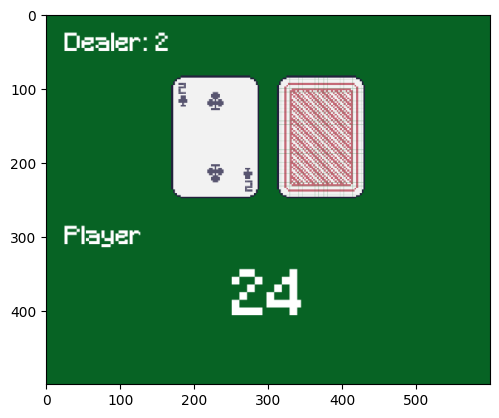

Player hand: [7, 4, 3, 10]
Dealer hand: [2, 6]
You lose!


In [46]:
# Reuse the show_policy function we implement for the lab on DP:

import time
import matplotlib.pyplot as plt
from IPython.display import clear_output

def show_policy(env, pi, n_episodes=1):
    for _ in range(n_episodes):
        state, info = env.reset()
        done = False;
        while not done:
            action = pi(state);
            state, reward, terminated, truncated, info = env.step(action);
            if(terminated or truncated): done = True;
            clear_output(wait=True);
            plt.imshow(env.render());
            plt.show();    

    # Show real cards from env internals
    print("Player hand:", env.unwrapped.player)
    print("Dealer hand:", env.unwrapped.dealer)
    
    if(reward == 1): print('You win!');
    elif(reward == -1): print('You lose!');
    else: print('Draw!');            

show_policy(blackjack, pi_random);

4 - Write a brute-force function in order to evaluate the probability of success and the average return obtained by a policy, the evaluate the random policy:

In [56]:
# You can reuse the "evaluate" function we implment for the lab on DP, 
# however pay attention on how to calculte the success rate, you need to  
# consider that the agent reaches the goal if it obtains a reward of 1 at   
# the end of an episode.

def evaluate(env, pi, n_episodes=10000):
    success = 0;
    returns = []
    for _ in range(n_episodes):
        done = False;
        steps = 0;
        state, info = env.reset();
        returns.append(0.0)
        while not done:
            state, reward, terminated, truncated, info = env.step(pi(state))
            if(terminated or truncated):
                done = True;
            returns[-1] += reward;
            steps += 1;
        if terminated and reward == 1:
            success += 1;
    return (success/n_episodes)*100, np.mean(returns);

probability_success, mean_return = evaluate(blackjack, pi_random);

print("Probability of success ", probability_success, "%");
print("Obtains an average undiscounted return of ", mean_return);

Probability of success  28.449999999999996 %
Obtains an average undiscounted return of  -0.3876


5 - Notice that the state space is not a single integer, but a tuple of discrete states. In order to use the state as an index in the value function, you need to convert the tuple of states into a single value.

In [57]:
# To convert the tuple of discrete states 
# (Discrete(32), Discrete(11), Discrete(2)) into a single index, 
# you can treat the tuple as a coordinate in a 3D grid and 
# compute a unique index for each combination of values. 
# This is essentially flattening the multi-dimensional space 
# into a one-dimensional array. 
# Given a tuple of states (s1, s2, s3) where:
# - s1 is in the range 0 to 31 (32 possible values),
# - s2 is in the range 0 to 10 (11 possible values),
# - s3 is in the range 0 to 1 (2 possible values),
# You can calculate the index by assuming that s3 is the least 
# significant and s1 is the most significant:

# index = s1 * (11 * 2) + s2 * 2 + s3

def state_to_index(s1, s2, s3):
    index = s1 * (11 * 2) + s2 * 2 + s3
    return index

6 - Use Double Q-learning to calculate the optimal policy and the optimal state-value function:

In [6]:
# You can reuse the function we apply to the Slippery Walk environment, in particular
# select_action() to use an epsilon greedy exploration strategy, decay_schedule() to
# calculare learning rate and epsilon values and double_q_learning() to implement the
# algorithm. However, you need to use the state_to_index() function to convert the 
# state into an index.

In [58]:
def select_action(state, q, epsilon=0.1):

    # if the random number is greater than epsilon, 
    if np.random.uniform() > epsilon:
        # pick the action with the highest Q value
        action = np.argmax(q[state]);
    else:
        # otherwise, pick a random action
        action = np.random.randint(len(q[0]));

    return action;

In [59]:
def decay_schedule(init_value, min_value, decay_steps, max_steps):

    # calculate the number of the remaining steps after the decay
    rem_steps = max_steps - decay_steps;

    # logspace returns numbers spaced evenly on a log scale
    # base^start is the starting value of the sequence,
    # base^stop is the final value of the sequence
    # num is the number of values to generate
    # base is the base of the log space
    values = np.logspace(start=0, stop=-2, num=decay_steps, base=10);

    # because the values may not end exactly at 0, given it’s the log, 
    # we change them to be between 0 and 1 so that the curve looks smooth and nice.
    values = (values - values.min()) / (values.max() - values.min());

    # linear transformation and get points between init_value and min_value
    values = (init_value - min_value) * values + min_value;

    # repeats the rightmost value rem_step number of times
    values = np.pad(values, (0, rem_steps), 'edge');

    return values;

In [60]:
def double_q_learning(env, gamma=0.99, 
                      init_alpha=0.5, min_alpha=0.01, 
                      init_epsilon=1.0, min_epsilon=0.1, 
                      decay_episodes=2000, n_episodes=3000):

    # calculate the observation space size
    n_states = state_to_index(env.observation_space[0].n, env.observation_space[1].n, int(env.observation_space[2].n));

    # calculate the learning rate schedule for all episodes    
    alphas = decay_schedule(init_alpha, min_alpha, decay_episodes, n_episodes);

    # calculate epsilon for all episodes   
    epsilons = decay_schedule(init_epsilon, min_epsilon, decay_episodes, n_episodes);

    # initialize the two action-value functions
    q1 = np.zeros((n_states, env.action_space.n), dtype=float);
    q2 = np.zeros((n_states, env.action_space.n), dtype=float);
    
    # the episode loop    
    for e in range(n_episodes):

        # we start episode by resetting the environment and the done flag
        state, done = env.reset(), False;
        state = state_to_index(state[0][0], state[0][1], int(state[0][2]));

         # repeat until we hit a terminal state
        while not done:
            
            # we use the mean of our two action-value functions to select action 
            action = select_action(state, (q1 + q2)/2., epsilons[e]);

            # step the environment using that action
            next_state, reward, terminated, truncated, info = env.step(action);
            next_state = state_to_index(next_state[0], next_state[1], int(next_state[2]));
            if(terminated or truncated):
                done = True;
            
            # flip a coin to determine an update to q1 or q2
            if np.random.randint(2):

                # use the action q1 thinks is best...
                argmax_q1 = np.argmax(q1[next_state]);
                
                # ...but get the value from q2 to calculate the target
                dq_learning_target = reward + gamma * q2[next_state][argmax_q1];

                # calculate the error 
                dq_learning_error = dq_learning_target - q1[state][action];
                
                # update q1
                q1[state][action] = q1[state][action] + alphas[e] * dq_learning_error;

            else:
                
                # use the action q2 thinks is best...
                argmax_q2 = np.argmax(q2[next_state]);
                
                # ...but get the value from q1 to calculate the target
                dq_learning_target = reward + gamma * q1[next_state][argmax_q2];
                dq_learning_error = dq_learning_target - q2[state][action];
                
                # update q2
                q2[state][action] = q2[state][action] + alphas[e] * dq_learning_error;
            
            # update state
            state = next_state;
        
        # extract the value functions
        q = (q1 + q2)/2.;
        v = np.max(q, axis=1);

        # and the greedy policy
        def pi(s):
            return np.argmax(q[state_to_index(s[0], s[1], int(s[2]))]);
            
    return q, v, pi;

In [61]:
q, v, pi = double_q_learning(blackjack);

7 - Calculate the performance of the obtained optimal policy using the brute force approach:

In [68]:
# You can reuse the "evaluation" function written before, 
# in order to evaluate the optimal policy

probability_success, mean_return = evaluate(blackjack, pi);
print("Probability of success ", probability_success, "%");
print("Obtains an average undiscounted return of ", mean_return);

Probability of success  40.839999999999996 %
Obtains an average undiscounted return of  -0.1018


8  - Show the optimal policy:

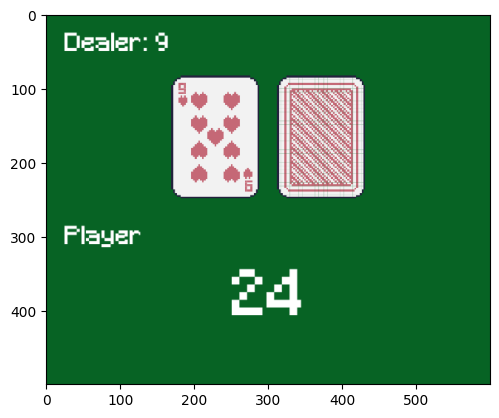

Player hand: [1, 5, 2, 6, 10]
Dealer hand: [9, 2]
You lose!


In [87]:
# You can reuse the "show_policy" function written before, 
# in order to show the optimal policy

show_policy(blackjack, pi, n_episodes=1)